# 04 · Does more data help? Learning curves over two orders of magnitude (Figure 3)

**Hypothesis H3.** More data helps any model whose hypothesis class contains a good classifier; the
quadratic model of the mock paper cannot improve because its *infinite-data* accuracy is capped at 56.5%
(notebook 02), so its flat curve measures approximation error, not the value of data.

**Design.** For each split seed (0–4) we train on nested random subsets of the training split of size
250, 500, …, up to the full split (7,200 / 12,000 / 19,200 for $n$ = 20 / 30 / 40); the validation and test
splits are held fixed.  Models: the mock paper's quadratic logistic regression, our MLP (configuration chosen in
notebook 03) and our sparse polynomial logistic regression (selection and $C$ chosen on validation data).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

from krypto.data import load, split, NS, SEEDS, TARGET
from krypto.polynomial import poly_logreg, SparsePolyLogReg
from krypto.selection import greedy_forward_selection
from krypto.mlp import mlp, train, accuracy, set_seed
from krypto.stats import mean_ci, save_json, load_json
from krypto.energy import track
from krypto.plotting import use_paper_style, save, FULL, COLORS, pct

print("plot backend:", use_paper_style())
mlp_config = {int(k): v for k, v in load_json("mlp_config.json").items()}
limit = load_json("poly_limit.json")
QUAD_LIMIT = limit["limit"]["2"] if limit else 0.5 * (1 + 9 / 64) * (1 - 2 * 0.039) + 0.039
print("MLP configurations:", mlp_config, " quadratic infinite-data limit:", round(QUAD_LIMIT, 4))


def sizes_for(n_train):
    return [m for m in (250, 500, 1000, 2000, 4000, 8000, 16000) if m < n_train] + [n_train]

plot backend: usetex
MLP configurations: {20: {'depth': 3, 'dropout': 0.2}, 30: {'depth': 3, 'dropout': 0.2}, 40: {'depth': 3, 'dropout': 0.2}}  quadratic infinite-data limit: 0.5648


In [2]:
curves = {n: {"sizes": None, "MLP": {}, "Sparse poly": {}, "Quadratic LR": {}} for n in NS}
for n in NS:
    X, y = load(f"kryptonite-{n}")
    with track(f"04_learning_curves_n{n}"):
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed)
            order = np.random.default_rng(seed).permutation(len(y_tr))      # nested subsets
            sizes = sizes_for(len(y_tr))
            curves[n]["sizes"] = sizes
            for m in sizes:
                Xm, ym = X_tr[order[:m]], y_tr[order[:m]]
                set_seed(seed)
                net, _ = train(mlp(n, 512, **mlp_config[n]), Xm, ym, X_va, y_va, seed=seed)
                curves[n]["MLP"].setdefault(m, []).append(accuracy(net, X_te, y_te))
                S, _ = greedy_forward_selection(Xm, ym, X_va, y_va)
                fits = [SparsePolyLogReg(S, 10, C).fit(Xm, ym) for C in (0.85, 10, 100, 1000, 10000)]
                best = max(fits, key=lambda f: f.score(X_va, y_va))
                curves[n]["Sparse poly"].setdefault(m, []).append(best.score(X_te, y_te))
                curves[n]["Quadratic LR"].setdefault(m, []).append(poly_logreg(Xm, ym, X_te, y_te, 2))
                print(f"n={n} seed={seed} N={m:6d}: MLP {curves[n]['MLP'][m][-1]:.3f}  "
                      f"sparse poly {curves[n]['Sparse poly'][m][-1]:.3f}  quadratic {curves[n]['Quadratic LR'][m][-1]:.3f}",
                      flush=True)
save_json({str(n): {"sizes": c["sizes"], **{k: {str(m): v for m, v in c[k].items()}
                                             for k in ("MLP", "Sparse poly", "Quadratic LR")}}
           for n, c in curves.items()}, "learning_curves.json")

n=20 seed=0 N=   250: MLP 0.492  sparse poly 0.512  quadratic 0.522


n=20 seed=0 N=   500: MLP 0.500  sparse poly 0.612  quadratic 0.519


n=20 seed=0 N=  1000: MLP 0.550  sparse poly 0.739  quadratic 0.530


n=20 seed=0 N=  2000: MLP 0.571  sparse poly 0.852  quadratic 0.548


n=20 seed=0 N=  4000: MLP 0.832  sparse poly 0.938  quadratic 0.560


n=20 seed=0 N=  7200: MLP 0.940  sparse poly 0.954  quadratic 0.554


... (98 outputs left out)

n=40 seed=4 N=  8000: MLP 0.583  sparse poly 0.958  quadratic 0.522


n=40 seed=4 N= 16000: MLP 0.950  sparse poly 0.959  quadratic 0.528


n=40 seed=4 N= 19200: MLP 0.953  sparse poly 0.959  quadratic 0.534


[track] 04_learning_curves_n40: 2951.0 s


## Smallest training-set size reaching the 90% target (mean over seeds, log-linear interpolation)

In [3]:
def n_at_target(sizes, means, target=TARGET):
    for (m0, a0), (m1, a1) in zip(zip(sizes, means), zip(sizes[1:], means[1:])):
        if a0 < target <= a1:
            return float(np.exp(np.log(m0) + (target - a0) / (a1 - a0) * (np.log(m1) - np.log(m0))))
    return None if means[-1] < target else float(sizes[0])


thresholds = {}
for n in NS:
    for model in ("MLP", "Sparse poly", "Quadratic LR"):
        sizes = curves[n]["sizes"]
        means = [np.mean(curves[n][model][m]) for m in sizes]
        thresholds[(n, model)] = n_at_target(sizes, means)
        print(f"n={n} {model:13s}: accuracy at full data {means[-1]:.3f};  N needed for 90%: "
              f"{thresholds[(n, model)] if thresholds[(n, model)] is None else round(thresholds[(n, model)])}")
save_json({f"{n}|{m}": v for (n, m), v in thresholds.items()}, "learning_curve_thresholds.json")

n=20 MLP          : accuracy at full data 0.938;  N needed for 90%: 5461
n=20 Sparse poly  : accuracy at full data 0.956;  N needed for 90%: 2922
n=20 Quadratic LR : accuracy at full data 0.539;  N needed for 90%: None
n=30 MLP          : accuracy at full data 0.953;  N needed for 90%: 7614
n=30 Sparse poly  : accuracy at full data 0.960;  N needed for 90%: 2817
n=30 Quadratic LR : accuracy at full data 0.529;  N needed for 90%: None
n=40 MLP          : accuracy at full data 0.951;  N needed for 90%: 14029
n=40 Sparse poly  : accuracy at full data 0.958;  N needed for 90%: 2903
n=40 Quadratic LR : accuracy at full data 0.531;  N needed for 90%: None


## Figure 3

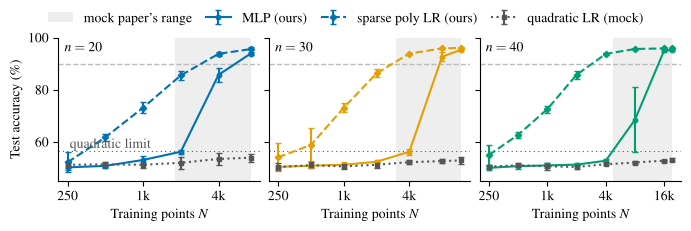

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(FULL, 2.2), sharey=True)
styles = {"MLP": ("-", "o", None), "Sparse poly": ("--", "D", None), "Quadratic LR": (":", "s", COLORS["gray"])}
labels = {"MLP": "MLP (ours)", "Sparse poly": "sparse poly LR (ours)", "Quadratic LR": "quadratic LR (mock)"}
for ax, n in zip(axes, NS):
    sizes = curves[n]["sizes"]
    full = sizes[-1]
    ax.axvspan(full / 4, full, color="#eeeeee", lw=0, label="mock paper's range")
    ax.axhline(100 * TARGET, color="#bbbbbb", ls="--", lw=1)
    ax.axhline(100 * QUAD_LIMIT, color=COLORS["gray"], lw=0.8, ls=(0, (1, 3)))
    for model, (ls, mk, col) in styles.items():
        st = np.array([mean_ci(curves[n][model][m]) for m in sizes]) * 100
        ax.errorbar(sizes, st[:, 0], yerr=st[:, 1], ls=ls, marker=mk, ms=3.2, capsize=2,
                    color=col or COLORS[n], label=labels[model])
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([250, 1000, 4000, 16000]))
    ax.xaxis.set_major_formatter(FixedFormatter(["250", "1k", "4k", "16k"]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Training points $N$"); ax.set_ylim(45, 100)
    ax.text(0.03, 0.97, f"$n={n}$", transform=ax.transAxes, va="top")
axes[0].set_ylabel(pct("Test accuracy (%)"))
axes[0].text(260, 100 * QUAD_LIMIT + 1.2, "quadratic limit", color=COLORS["gray"])
handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, ncol=4, loc="outside upper center", handlelength=1.8, columnspacing=1.0)
save(fig, "fig3_learning_curves")
plt.show()

**Reading Figure 3.** The mock paper only looked inside the grey band (25–100% of the training split) and only at
the quadratic model, whose curve can never exceed its infinite-data limit (dotted, 56.5%).  Models that can
represent the label function improve sharply with data: the MLP and the sparse polynomial model cross 90% within
the available data for every $n$, and the amount of data needed grows with the number of distractor coordinates.